## Edge-level thread corpus descriptives

Coverage, text length, and training feasibility for the London undirected edge corpus.
The notebook reads from PostgreSQL; it does not modify the corpus table.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

CONNECTION_PATH = "/home/ilyesvirag/twitter/venv/connection.json"
TABLE = "interaction_edge_thread_corpus_london"

with open(CONNECTION_PATH, encoding="utf-8") as f:
    cfg = json.load(f)

engine = create_engine(URL.create(
    drivername="postgresql+psycopg2",
    username=cfg["user"], password=cfg["password"],
    host=cfg["host"], port=cfg["port"], database=cfg["database"]
), pool_pre_ping=True)

def query(sql):
    return pd.read_sql(text(sql), engine)


### 1. Overall corpus size

Includes raw and cleaned word counts; cleaned counts require the cleaning step.


In [2]:
overall = query(f"""
SELECT
    COUNT(*) AS n_edges,
    COUNT(*) FILTER (WHERE n_threads > 1) AS n_edges_multiple_threads,
    COUNT(*) FILTER (WHERE n_thread_tweets > 1) AS n_edges_multiple_thread_tweets,
    SUM(n_interaction_tweets) AS total_interaction_tweets,
    SUM(n_threads) AS total_edge_thread_links,
    SUM(n_thread_tweets) AS total_thread_tweets,
    SUM(n_text_characters) AS total_text_characters,
    SUM(n_text_words) AS total_text_words,
    COUNT(edge_thread_cleaned) AS n_edges_with_cleaned_text,
    SUM(n_cleaned_words) AS total_cleaned_words,
    AVG(n_threads) AS mean_threads_per_edge,
    AVG(n_thread_tweets) AS mean_thread_tweets_per_edge,
    AVG(n_text_characters) AS mean_characters_per_edge,
    AVG(n_text_words) AS mean_words_per_edge,
    AVG(n_cleaned_words) AS mean_cleaned_words_per_edge
FROM {TABLE}
""")


In [4]:
# Overall corpus statistics: readable values and measure definitions

descriptions = {
    "n_edges": "Number of unique user pairs with at least one mention/reply interaction",
    "n_edges_multiple_threads": "Number of user pairs whose interactions are associated with more than one conversation thread",
    "n_edges_multiple_thread_tweets": "Number of user pairs whose associated conversation threads contain more than one tweet in total, including tweets by other users",
    "total_interaction_tweets": "Total number of direct mention/reply interaction tweets between user pairs, summed across all edges",
    "total_edge_thread_links": "Total number of conversation threads associated with user pairs, counting each thread separately for each pair",
    "total_thread_tweets": "Total number of tweets in the conversation threads associated with user pairs, including tweets by other users and counting repeated threads across edges",
    "total_text_characters": "Total number of characters across all edge-level texts, each combining tweets from all conversation threads associated with a user pair",
    "total_text_words": "Total number of words across all edge-level texts, combining all associated conversation threads before cleaning",
    "n_edges_with_cleaned_text": "Number of user pairs with non-missing cleaned text combining their associated conversation threads",
    "total_cleaned_words": "Total number of words across all edge-level texts after cleaning, combining all associated conversation threads",
    "mean_threads_per_edge": "Average number of distinct conversation threads associated with each user pair",
    "mean_thread_tweets_per_edge": "Average number of tweets across all conversation threads associated with each user pair, including tweets by other users",
    "mean_characters_per_edge": "Average number of characters per user pair, combining all associated conversation threads",
    "mean_words_per_edge": "Average number of words per user pair, combining all associated conversation threads before cleaning",
    "mean_cleaned_words_per_edge": "Average number of words per user pair, combining all associated conversation threads after cleaning",
}

overall_table = overall.T.reset_index()
overall_table.columns = ["Measure", "Value"]

overall_table["Description"] = overall_table["Measure"].map(descriptions)

overall_table["Value"] = overall_table.apply(
    lambda row: (
        f"{row['Value']:,.2f}"
        if row["Measure"].startswith("mean_")
        else f"{row['Value']:,.0f}"
    ),
    axis=1
)

display(overall_table)

,Measure,Value,Description
0,n_edges,"39,946,047",Number of unique user pairs with at least one ...
1,n_edges_multiple_threads,"10,069,818",Number of user pairs whose interactions are as...
2,n_edges_multiple_thread_tweets,"18,291,276",Number of user pairs whose associated conversa...
3,total_interaction_tweets,"116,875,825",Total number of direct mention/reply interacti...
4,total_edge_thread_links,"89,844,661",Total number of conversation threads associate...
5,total_thread_tweets,"241,900,830",Total number of tweets in the conversation thr...
6,total_text_characters,"55,769,501,555",Total number of characters across all edge-lev...
7,total_text_words,"6,009,810,740",Total number of words across all edge-level te...
8,n_edges_with_cleaned_text,"39,946,047",Number of user pairs with non-missing cleaned ...
9,total_cleaned_words,"6,009,967,204",Total number of words across all edge-level te...


### 2. Edge-level distributions

In [5]:
variables = [
    "n_interaction_tweets",
    "n_threads",
    "n_thread_tweets",
    "n_text_characters",
    "n_text_words",
    "n_cleaned_words"
]

distribution_descriptions = {
    "n_interaction_tweets": "Number of direct mention/reply interaction tweets between the two users forming an edge",
    "n_threads": "Number of distinct conversation threads associated with a user pair's interactions",
    "n_thread_tweets": "Total number of tweets across all conversation threads associated with a user pair, including tweets by other users",
    "n_text_characters": "Number of characters in the combined text of all conversation threads associated with a user pair",
    "n_text_words": "Number of words in the combined text of all conversation threads associated with a user pair, before cleaning",
    "n_cleaned_words": "Number of words in the combined text of all conversation threads associated with a user pair, after cleaning",
}

parts = []

for v in variables:
    x = query(f"""
        SELECT
            '{v}' AS variable,
            AVG({v}) AS mean,
            PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY {v}) AS median,
            PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY {v}) AS p75,
            PERCENTILE_CONT(0.90) WITHIN GROUP (ORDER BY {v}) AS p90,
            PERCENTILE_CONT(0.95) WITHIN GROUP (ORDER BY {v}) AS p95,
            PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY {v}) AS p99,
            MAX({v}) AS max
        FROM {TABLE}
    """)
    parts.append(x)

distribution = pd.concat(parts, ignore_index=True)

# Add variable definitions
distribution.insert(
    1,
    "Description",
    distribution["variable"].map(distribution_descriptions)
)

# Format values for display without changing the underlying data
distribution_display = distribution.style.format({
    "mean": "{:,.2f}",
    "median": "{:,.0f}",
    "p75": "{:,.0f}",
    "p90": "{:,.0f}",
    "p95": "{:,.0f}",
    "p99": "{:,.0f}",
    "max": "{:,.0f}",
})

display(distribution_display)

,variable,Description,mean,median,p75,p90,p95,p99,max
0,n_interaction_tweets,Number of direct mention/reply interaction tweets between the two users forming an edge,2.93,1,2,4,8,29,"17,761"
1,n_threads,Number of distinct conversation threads associated with a user pair's interactions,2.25,1,2,3,6,20,"17,321"
2,n_thread_tweets,"Total number of tweets across all conversation threads associated with a user pair, including tweets by other users",6.06,1,3,8,15,62,"18,863"
3,n_text_characters,Number of characters in the combined text of all conversation threads associated with a user pair,"1,396.12",143,323,866,"1,740","7,460","5,350,435"
4,n_text_words,"Number of words in the combined text of all conversation threads associated with a user pair, before cleaning",150.45,21,47,124,249,"1,036","480,274"
5,n_cleaned_words,"Number of words in the combined text of all conversation threads associated with a user pair, after cleaning",150.45,21,47,124,249,"1,036","480,274"


### 3. How many edges have enough text?

Threshold measures (calculated separately for each user-pair edge):
- thread tweets: Total number of tweets in all conversation threads associated
                  with the edge, including tweets by other users.
- raw words:     Total number of words in the combined text of all associated
                  conversation threads, before text cleaning.
- cleaned words: Total number of words in the same combined text after cleaning.

threshold: Minimum number of thread tweets or words required (>= threshold).

n_edges:   Number of user pairs meeting the threshold.

share_edges: Proportion of all user pairs meeting the threshold (0–1).

In [6]:
thresholds = query(f"""
WITH base AS (SELECT COUNT(*)::numeric AS n FROM {TABLE})
SELECT 'thread tweets' AS measure, x.threshold,
       COUNT(*) AS n_edges,
       COUNT(*) / base.n AS share_edges
FROM {TABLE}, base
CROSS JOIN (VALUES (1),(2),(5),(10),(20),(50),(100),(200)) AS x(threshold)
WHERE n_thread_tweets >= x.threshold
GROUP BY x.threshold, base.n
UNION ALL
SELECT 'raw words', x.threshold, COUNT(*), COUNT(*) / base.n
FROM {TABLE}, base
CROSS JOIN (VALUES (5), (10), (20), (50),(100),(250),(500),(1000),(2500),(5000),(10000)) AS x(threshold)
WHERE n_text_words >= x.threshold
GROUP BY x.threshold, base.n
UNION ALL
SELECT 'cleaned words', x.threshold, COUNT(*), COUNT(*) / base.n
FROM {TABLE}, base
CROSS JOIN (VALUES (5), (10), (20), (50),(100),(250),(500),(1000),(2500),(5000),(10000)) AS x(threshold)
WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= x.threshold
GROUP BY x.threshold, base.n
ORDER BY measure, threshold
""")
thresholds

,measure,threshold,n_edges,share_edges
0,cleaned words,5,37374139,0.935615
1,cleaned words,10,32079164,0.803062
2,cleaned words,20,21177733,0.530158
3,cleaned words,50,9451943,0.236618
4,cleaned words,100,4939842,0.123663
5,cleaned words,250,1991059,0.049844
6,cleaned words,500,936590,0.023446
7,cleaned words,1000,416798,0.010434
8,cleaned words,2500,147652,0.003696
9,cleaned words,5000,76704,0.001920


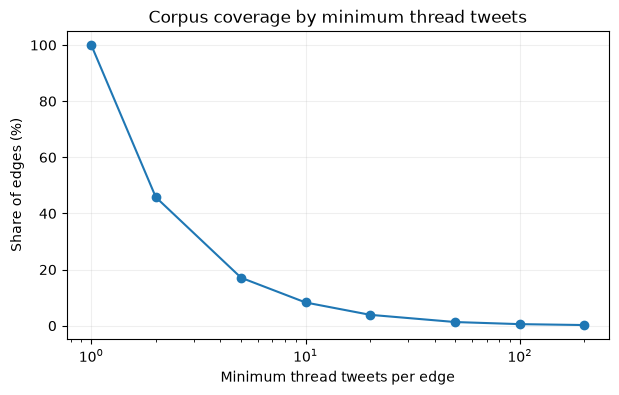

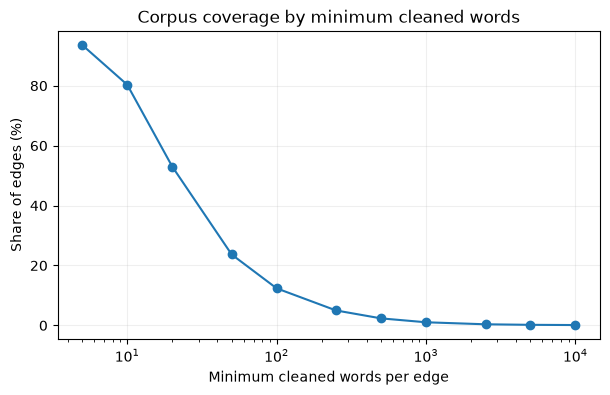

In [8]:
for measure in ["thread tweets", "cleaned words"]:
    d = thresholds[thresholds["measure"] == measure]
    plt.figure(figsize=(7, 4))
    plt.plot(d["threshold"], d["share_edges"] * 100, marker="o")
    plt.xscale("log")
    plt.xlabel(f"Minimum {measure} per edge")
    plt.ylabel("Share of edges (%)")
    plt.title(f"Corpus coverage by minimum {measure}")
    plt.grid(alpha=0.2)
    plt.show()


### 4. Number of threads per edge

In [6]:
thread_counts = query(f"""
SELECT
    CASE
        WHEN n_threads = 1 THEN '1'
        WHEN n_threads = 2 THEN '2'
        WHEN n_threads BETWEEN 3 AND 5 THEN '3-5'
        WHEN n_threads BETWEEN 6 AND 10 THEN '6-10'
        WHEN n_threads BETWEEN 11 AND 20 THEN '11-20'
        ELSE '21+'
    END AS n_threads_group,
    COUNT(*) AS n_edges
FROM {TABLE}
GROUP BY 1
""")
order = ['1','2','3-5','6-10','11-20','21+']
thread_counts['n_threads_group'] = pd.Categorical(thread_counts['n_threads_group'], categories=order, ordered=True)
thread_counts = thread_counts.sort_values('n_threads_group')
thread_counts['share_edges'] = thread_counts['n_edges'] / thread_counts['n_edges'].sum()
thread_counts

,n_threads_group,n_edges,share_edges
0,1,29876229,0.747915
2,2,4624861,0.115778
4,3-5,3324429,0.083223
5,6-10,1166421,0.029200
1,11-20,556871,0.013941
3,21+,397236,0.009944


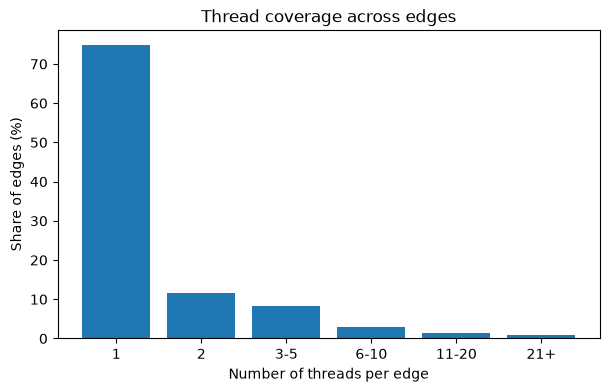

In [7]:
plt.figure(figsize=(7, 4))
plt.bar(thread_counts['n_threads_group'].astype(str), thread_counts['share_edges'] * 100)
plt.xlabel('Number of threads per edge')
plt.ylabel('Share of edges (%)')
plt.title('Thread coverage across edges')
plt.show()


### 5. Concentration of cleaned text across edges

Edges are ranked by the total number of cleaned words in their associated
conversation threads (including tweets by other users).

- share_words_top_1pct_edges:  Share of all cleaned words contained in the top 1% of edges.
- share_words_top_5pct_edges:  Share of all cleaned words contained in the top 5% of edges.
- share_words_top_10pct_edges: Share of all cleaned words contained in the top 10% of edges.
- share_words_top_25pct_edges: Share of all cleaned words contained in the top 25% of edges.

Only edges with non-missing cleaned text are included.
Values range from 0 to 1 (multiply by 100 for percentages).
A higher concentration indicates that a relatively small share of user pairs accounts for a large proportion of the corpus's cleaned text.

In [8]:
concentration = query(f"""
WITH ranked AS (
    SELECT n_cleaned_words,
           NTILE(100) OVER (ORDER BY n_cleaned_words DESC) AS pct
    FROM {TABLE}
    WHERE edge_thread_cleaned IS NOT NULL
), totals AS (
    SELECT SUM(n_cleaned_words)::numeric AS total_words FROM ranked
)
SELECT
    SUM(n_cleaned_words) FILTER (WHERE pct <= 1) / total_words AS share_words_top_1pct_edges,
    SUM(n_cleaned_words) FILTER (WHERE pct <= 5) / total_words AS share_words_top_5pct_edges,
    SUM(n_cleaned_words) FILTER (WHERE pct <= 10) / total_words AS share_words_top_10pct_edges,
    SUM(n_cleaned_words) FILTER (WHERE pct <= 25) / total_words AS share_words_top_25pct_edges
FROM ranked, totals
GROUP BY total_words
""")
concentration.T

,0
share_words_top_1pct_edges,0.655899
share_words_top_5pct_edges,0.779620
share_words_top_10pct_edges,0.837127
share_words_top_25pct_edges,0.910714



### 6. Relationship between interaction intensity and available text



Here we examine the relationship between direct interaction intensity, conversation-thread coverage, and text volume at the user-pair (edge) level. Each observation represents a unique pair of users connected by at least one mention/reply interaction.

**Variable definitions**

| Variable | Description |
|---|---|
| `n_interaction_tweets` | Number of direct mention/reply interaction tweets between the two users forming an edge. |
| `n_threads` | Number of distinct conversation threads associated with the user pair's interactions. |
| `n_thread_tweets` | Total number of tweets across all associated conversation threads, including tweets by other users. |
| `n_text_words` | Total number of words in the combined text of all associated conversation threads, before cleaning. |
| `n_cleaned_words` | Total number of words in the combined text of all associated conversation threads, after cleaning. |

**Important:** Although all measures are calculated at the edge level, the thread-based text measures include tweets by other users. Therefore, text volume does not necessarily represent direct communication between the two users.

**Key correlations and their interpretation**

| Correlation | Research question |
|---|---|
| `n_interaction_tweets` × `n_threads` | Do user pairs with more direct interactions participate in a greater number of distinct conversation threads? |
| `n_interaction_tweets` × `n_cleaned_words` | Do more frequently interacting user pairs have larger associated text corpora? |
| `n_threads` × `n_thread_tweets` | Is a greater number of associated threads linked to a larger number of collected tweets? |
| `n_threads` × `n_cleaned_words` | Are user pairs associated with more threads also associated with larger text corpora? |
| `n_thread_tweets` × `n_cleaned_words` | How closely does the number of collected tweets correspond to the amount of usable text? |
| `n_text_words` × `n_cleaned_words` | Do user pairs with more text before cleaning also have more text after cleaning? |

**Interpretation**

Spearman rank correlations are calculated across a sample of up to 200,000 edges. Positive correlations indicate that user pairs with higher values on one measure tend to have higher values on another.

In [9]:
sample = query(f"""
SELECT n_interaction_tweets, n_threads, n_thread_tweets, n_text_words, n_cleaned_words
FROM {TABLE}
TABLESAMPLE SYSTEM (1)
LIMIT 200000
""")
sample.corr(method='spearman')

,n_interaction_tweets,n_threads,n_thread_tweets,n_text_words,n_cleaned_words
n_interaction_tweets,1.000000,0.869374,0.786957,0.625933,0.625927
n_threads,0.869374,1.000000,0.686795,0.545825,0.545822
n_thread_tweets,0.786957,0.686795,1.000000,0.789218,0.789210
n_text_words,0.625933,0.545825,0.789218,1.000000,0.999997
n_cleaned_words,0.625927,0.545822,0.789210,0.999997,1.000000


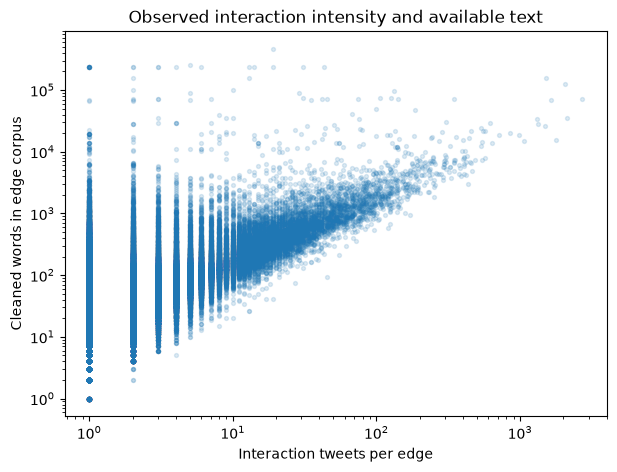

In [10]:
plot_sample = sample[(sample.n_interaction_tweets > 0) & (sample.n_cleaned_words > 0)].copy()
plt.figure(figsize=(7, 5))
plt.scatter(plot_sample['n_interaction_tweets'], plot_sample['n_cleaned_words'], s=8, alpha=0.15)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Interaction tweets per edge')
plt.ylabel('Cleaned words in edge corpus')
plt.title('Observed interaction intensity and available text')
plt.show()


### 7. Largest edge corpora
Identify the 30 user-pair edges with the largest cleaned text corpora.


In [11]:
largest = query(f"""
SELECT city, user_id1, user_id2, n_interaction_tweets, n_threads,
       n_thread_tweets, n_text_characters, n_text_words, n_cleaned_words
FROM {TABLE}
ORDER BY n_cleaned_words DESC
LIMIT 30
""")
largest

,city,user_id1,user_id2,n_interaction_tweets,n_threads,n_thread_tweets,n_text_characters,n_text_words,n_cleaned_words
0,london,70656697,74409768,745,52,7751,5350435,480274,480274
1,london,753461283442323456,1065308082048241666,279,28,7517,5349510,478328,478328
2,london,500679509,750729281387565060,1791,52,7695,5328599,478294,478294
3,london,74409768,458412207,410,77,7683,5320914,477354,477354
4,london,70656697,753461283442323456,105,26,7372,5297129,473026,473026
5,london,721971909752156160,750729281387565060,1763,12,7365,5280328,471658,471658
6,london,74409768,2767054761,676,11,7357,5279508,471620,471620
7,london,239902611,753461283442323456,70,9,7306,5285917,471576,471576
8,london,730602471979159552,753461283442323456,16,4,7303,5285567,471549,471549
9,london,4040483387,750729281387565060,168,7,7330,5273428,471018,471018


### 9. Full-corpus BERTopic feasibility: settings and eligible population

The following diagnostics are designed for training on **all eligible edges**, rather than fitting on a sample and transforming the remainder. `n_cleaned_words >= 10` defines eligibility. The 500-word window is a *random contiguous window* per eligible edge; it does not increase the number of training documents. Estimates below are planning figures, not benchmarks of full-data UMAP/HDBSCAN.

The 500-word window is an optional pre-embedding sampling cap, not the transformer token limit. The MiniLM embedding model uses a maximum of 128 transformer tokens; actual truncation depends on tokenization.


In [12]:
import numpy as np
from pathlib import Path

MIN_CLEANED_WORDS = 10
MAX_WORD_WINDOW = 500  # optional whitespace-word window, NOT the transformer token limit
MODEL_MAX_TOKENS = 128  # sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
EMBEDDING_DIM = 384  # paraphrase-multilingual-MiniLM-L12-v2; verified below if model loads
UMAP_COMPONENTS = 5
EMBEDDING_BATCH_SIZE = 64
BENCHMARK_ROWS = 2000
RUN_EMBEDDING_BENCHMARK = False  # Enable only when benchmarking is needed
RUN_TOKEN_LENGTH_CHECK = False  # Enable only when checking token lengths
RUN_EXACT_DUPLICATE_CHECK = False  # expensive on a large corpus


### 10. Cleaned-text availability, eligible edges, and training-text mass

In [13]:
eligible = query(f"""
SELECT COUNT(*) AS all_edges,
       COUNT(*) FILTER (WHERE edge_thread_cleaned IS NOT NULL) AS edges_with_cleaned_text,
       COUNT(*) FILTER (WHERE n_cleaned_words IS NULL) AS missing_cleaned_word_counts,
       COUNT(*) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}) AS eligible_edges,
       COUNT(*) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words < {MIN_CLEANED_WORDS}) AS short_edges,
       SUM(n_cleaned_words) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}) AS eligible_cleaned_words,
       SUM(LEAST(n_cleaned_words, {MAX_WORD_WINDOW})) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}) AS windowed_words,
       COUNT(*) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words > {MAX_WORD_WINDOW}) AS edges_above_word_window,
       SUM(n_interaction_tweets) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}) AS eligible_interaction_tweets,
       SUM(n_threads) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}) AS eligible_edge_thread_links
FROM {TABLE}
""")
e = eligible.iloc[0]
eligible['eligible_edge_share'] = eligible.eligible_edges / eligible.all_edges
eligible['share_above_word_window'] = eligible.edges_above_word_window / eligible.eligible_edges
eligible['word_window_share'] = eligible.windowed_words / eligible.eligible_cleaned_words
eligible.T


,0
all_edges,3.994605e+07
edges_with_cleaned_text,3.994605e+07
missing_cleaned_word_counts,0.000000e+00
eligible_edges,3.207916e+07
short_edges,7.866883e+06
eligible_cleaned_words,5.964717e+09
windowed_words,2.114740e+09
edges_above_word_window,9.345820e+05
eligible_interaction_tweets,1.086793e+08
eligible_edge_thread_links,8.175615e+07


### 11. Cleaned-word length distribution and cutoff sensitivity

In [14]:
length_buckets = query(f"""
SELECT CASE WHEN n_cleaned_words IS NULL THEN 'missing'
            WHEN n_cleaned_words < 10 THEN '0-9'
            WHEN n_cleaned_words < 20 THEN '10-19'
            WHEN n_cleaned_words < 50 THEN '20-49'
            WHEN n_cleaned_words < 100 THEN '50-99'
            WHEN n_cleaned_words < 250 THEN '100-249'
            WHEN n_cleaned_words < 500 THEN '250-499'
            WHEN n_cleaned_words < 1000 THEN '500-999'
            WHEN n_cleaned_words < 2500 THEN '1000-2499'
            ELSE '2500+' END AS length_group,
       COUNT(*) AS n_edges,
       SUM(n_cleaned_words) AS cleaned_words,
       SUM(LEAST(n_cleaned_words, {MAX_WORD_WINDOW})) AS capped_words
FROM {TABLE}
GROUP BY 1
""")
order = ['missing','0-9','10-19','20-49','50-99','100-249','250-499','500-999','1000-2499','2500+']
length_buckets['length_group'] = pd.Categorical(length_buckets.length_group, categories=order, ordered=True)
length_buckets = length_buckets.sort_values('length_group')
length_buckets['edge_share'] = length_buckets.n_edges / length_buckets.n_edges.sum()
length_buckets


,length_group,n_edges,cleaned_words,capped_words,edge_share
0,0-9,7866883,4.524989e+07,45249887.0,0.196938
3,10-19,10901431,1.563167e+08,156316745.0,0.272904
4,20-49,11725790,3.607361e+08,360736069.0,0.293541
8,50-99,4512101,3.117043e+08,311704280.0,0.112955
2,100-249,2948783,4.520229e+08,452022938.0,0.073819
6,250-499,1054469,3.656645e+08,365664544.0,0.026397
7,500-999,519792,3.587047e+08,259896000.0,0.013012
1,1000-2499,269146,4.035175e+08,134573000.0,0.006738
5,2500+,147652,3.556050e+09,73826000.0,0.003696


In [15]:
cutoffs = query(f"""
SELECT x.min_words,
       COUNT(*) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= x.min_words) AS n_eligible,
       SUM(LEAST(n_cleaned_words, {MAX_WORD_WINDOW})) FILTER (WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= x.min_words) AS windowed_words
FROM {TABLE}
CROSS JOIN (VALUES (5),(10),(20),(30),(50),(75),(100)) AS x(min_words)
GROUP BY x.min_words ORDER BY x.min_words
""")
cutoffs['share_all_edges'] = cutoffs.n_eligible / int(e.all_edges)
cutoffs['share_windowed_words_vs_min10'] = cutoffs.windowed_words / float(e.windowed_words)
cutoffs


,min_words,n_eligible,windowed_words,share_all_edges,share_windowed_words_vs_min10
0,5,37374139,2.152026e+09,0.935615,1.017632
1,10,32079164,2.114740e+09,0.803062,1.000000
2,20,21177733,1.958423e+09,0.530158,0.926082
3,30,15120017,1.814505e+09,0.378511,0.858028
4,50,9451943,1.597687e+09,0.236618,0.755500
5,75,6486739,1.418908e+09,0.162388,0.670961
6,100,4939842,1.285982e+09,0.123663,0.608104


### 12. Database storage and available machine resources

PostgreSQL relation size includes indexes and TOAST. Python RAM, free disk and GPU memory are measured on the machine running the notebook, which may differ from the PostgreSQL server.

In [16]:
db_storage = query(f"""
SELECT pg_size_pretty(pg_relation_size('{TABLE}'::regclass)) AS table_heap,
       pg_size_pretty(pg_indexes_size('{TABLE}'::regclass)) AS indexes,
       pg_size_pretty(pg_total_relation_size('{TABLE}'::regclass)) AS total_with_toast_and_indexes,
       pg_total_relation_size('{TABLE}'::regclass) AS total_bytes
""")
db_storage.T


,0
table_heap,35 GB
indexes,3774 MB
total_with_toast_and_indexes,58 GB
total_bytes,62661025792


In [17]:
import os, shutil
import psutil
resources = {'cpu_count_logical': psutil.cpu_count(), 'cpu_count_physical': psutil.cpu_count(logical=False),
             'ram_total_gb': psutil.virtual_memory().total / 1e9, 'ram_available_gb': psutil.virtual_memory().available / 1e9,
             'disk_free_gb': shutil.disk_usage('/mnt/common-hdd/group-dirs/twitter-2025-project').free / 1e9}
try:
    import torch
    resources['cuda_available'] = torch.cuda.is_available()
    if torch.cuda.is_available():
        resources['gpu_name'] = torch.cuda.get_device_name(0)
        free, total = torch.cuda.mem_get_info(0)
        resources['gpu_free_gb'], resources['gpu_total_gb'] = free / 1e9, total / 1e9
except ImportError:
    resources['cuda_available'] = 'torch not installed'
pd.Series(resources, name='value').to_frame()


,value
cpu_count_logical,20
cpu_count_physical,20
ram_total_gb,135.166792
ram_available_gb,99.294241
disk_free_gb,344.216257
cuda_available,False


### 13. Minimum storage estimates for all eligible embeddings

These are *lower bounds*: they exclude model objects, nearest-neighbor indices, UMAP/HDBSCAN working arrays, Python/Pandas overhead, text storage, and temporary copies. UMAP/HDBSCAN full-data peak RAM cannot be inferred from the embedding matrix alone.

In [18]:
N = int(e.eligible_edges)
storage = pd.DataFrame([
    {'item': 'Sentence embeddings float32', 'dimensions': EMBEDDING_DIM, 'bytes_per_value': 4},
    {'item': 'Sentence embeddings float16 (disk only)', 'dimensions': EMBEDDING_DIM, 'bytes_per_value': 2},
    {'item': 'UMAP 5D float32', 'dimensions': UMAP_COMPONENTS, 'bytes_per_value': 4},
    {'item': 'Topic assignments int32', 'dimensions': 1, 'bytes_per_value': 4},
    {'item': 'One int64 row identifier', 'dimensions': 1, 'bytes_per_value': 8},
])
storage['eligible_edges'] = N
storage['estimated_gb_decimal'] = storage.dimensions * storage.bytes_per_value * N / 1e9
storage


,item,dimensions,bytes_per_value,eligible_edges,estimated_gb_decimal
0,Sentence embeddings float32,384,4,32079164,49.273596
1,Sentence embeddings float16 (disk only),384,2,32079164,24.636798
2,UMAP 5D float32,5,4,32079164,0.641583
3,Topic assignments int32,1,4,32079164,0.128317
4,One int64 row identifier,1,8,32079164,0.256633


### 14. Observed sampling and potential duplication

This diagnostic checks a small random page sample. It does **not** establish the global number of duplicate texts. Repeated thread context across different edges is expected and is a separate weighting issue.

In [19]:
text_sample = query(f"""
SELECT city, user_id1, user_id2, n_cleaned_words, n_interaction_tweets, n_threads,
       edge_thread_cleaned
FROM {TABLE} TABLESAMPLE SYSTEM (1) REPEATABLE (12345)
WHERE edge_thread_cleaned IS NOT NULL AND n_cleaned_words >= {MIN_CLEANED_WORDS}
LIMIT {BENCHMARK_ROWS}
""")
print('Sample rows:', len(text_sample))
if len(text_sample):
    print('Exact duplicate cleaned-text share in this sample:', f'{text_sample.edge_thread_cleaned.duplicated(keep=False).mean():.1%}')
    display(text_sample[['n_cleaned_words','n_interaction_tweets','n_threads']].describe(percentiles=[.5,.9,.95,.99]))


Sample rows: 2000
Exact duplicate cleaned-text share in this sample: 2.1%


,n_cleaned_words,n_interaction_tweets,n_threads
count,2000.000000,2000.000000,2000.000000
mean,676.503000,6.771000,4.869000
std,8188.492634,20.090903,14.612686
min,10.000000,1.000000,1.000000
50%,23.000000,1.000000,1.000000
90%,828.100000,15.000000,10.000000
95%,1474.000000,34.000000,24.000000
99%,4759.000000,109.010000,73.010000
max,236611.000000,274.000000,222.000000


### 15. Transformer token truncation: optional diagnostic

The multilingual MiniLM model used in the pilot has a 128-token maximum. A 500-word window can therefore lose substantial text **before** embedding. This optional check reports tokenizer lengths for sampled full cleaned texts and for their capped windows; it does not modify the planned model.

**Important:** The 500-word window is a separate optional preprocessing choice, not the model limit. The embedding model accepts at most 128 transformer tokens (including special tokens). Enable `RUN_TOKEN_LENGTH_CHECK` to measure actual truncation on the sampled cleaned texts.


In [20]:
if RUN_TOKEN_LENGTH_CHECK and len(text_sample):
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    rng = np.random.default_rng(12345)
    def window(s):
        w = str(s).split()
        if len(w) <= MAX_WORD_WINDOW: return ' '.join(w)
        start = int(rng.integers(0, len(w) - MAX_WORD_WINDOW + 1))
        return ' '.join(w[start:start + MAX_WORD_WINDOW])
    model_texts = [window(s) for s in text_sample.edge_thread_cleaned]
    token_lengths = [len(tokenizer.encode(s, add_special_tokens=True, truncation=False)) for s in model_texts]
    display(pd.Series(token_lengths).describe(percentiles=[.5,.75,.9,.95,.99]).to_frame('transformer_tokens'))
    print('Share exceeding model token limit:', np.mean(np.array(token_lengths) > MODEL_MAX_TOKENS))
else:
    print('Skipped. Set RUN_TOKEN_LENGTH_CHECK=True to run.')


Skipped. Set RUN_TOKEN_LENGTH_CHECK=True to run.


### 16. Embedding throughput: optional small benchmark

Benchmark the actual server/GPU before projecting runtime. Results include only embedding computation, not database I/O, UMAP or HDBSCAN.

In [21]:
if RUN_EMBEDDING_BENCHMARK and len(text_sample):
    import time
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    # SentenceTransformer enforces the model token limit when encoding.
    texts = [' '.join(str(s).split()[:MAX_WORD_WINDOW]) for s in text_sample.edge_thread_cleaned]
    t0 = time.perf_counter()
    vectors = model.encode(texts, batch_size=EMBEDDING_BATCH_SIZE, show_progress_bar=True, convert_to_numpy=True)
    seconds = time.perf_counter() - t0
    rate = len(texts) / seconds
    display(pd.Series({'benchmark_documents': len(texts), 'seconds': seconds, 'documents_per_second': rate,
                       'projected_embedding_hours': N / rate / 3600, 'actual_embedding_dimension': vectors.shape[1]}).to_frame('value'))
else:
    print('Skipped. Set RUN_EMBEDDING_BENCHMARK=True to run.')


Skipped. Set RUN_EMBEDDING_BENCHMARK=True to run.


### 17. Full-data training decision sheet

Review the figures above before launching: eligible N, embedding disk/RAM lower bounds, free disk and RAM, token truncation, benchmark throughput, and sample text duplication. **Full-data UMAP and HDBSCAN remain the major unresolved scalability risks.** An end-to-end trial at increasing sizes (for example 100k → 500k → 1m) should measure peak RAM and runtime before launching on all eligible edges. Topic count and outlier shares at those sizes can also guide whether `min_cluster_size=100` remains sensible. The `distributions(.20)` reassignment is deliberately excluded from the initial full-data fit.